# Digital Image Processing with PyTorch — an in-depth notebook

Classic image processing — the ideas behind every camera app, scanner and computer-vision model — built **from scratch with
PyTorch tensor operations**, so you see exactly how each technique works. Torchvision is used at the end for production-style pipelines.

| # | Topic | # | Topic |
|---|---|---|---|
| 1 | Images as tensors: shape, dtype, layout | 8 | Morphology: erosion, dilation, opening, closing |
| 2 | Colour spaces: RGB, grayscale, HSV | 9 | Frequency domain with `torch.fft` |
| 3 | Point operations: brightness, contrast, gamma, thresholds | 10 | Pyramids, downsampling and aliasing |
| 4 | Histograms, equalisation and Otsu | 11 | Image quality metrics: MSE, PSNR, SSIM |
| 5 | Geometric transforms: resize, rotate, affine warps | 12 | Batch pipelines and augmentation with torchvision |
| 6 | Convolution: blur, sharpen, noise and denoising | 13 | From hand-made to learned filters (a tiny CNN) |
| 7 | Edge detection: Sobel, Laplacian, LoG | | |

Each section: **concept → code → real output → 🔍 what to notice → ✍️ exercise**. Images come bundled with scikit-learn and
scikit-image, so no downloads are needed. Everything runs on a CPU; set `device` to `"cuda"` to run the same code on a GPU.

## 0. Setup

In [1]:
import math, time
import numpy as np
import torch
import torch.nn.functional as F
from torch import nn
import matplotlib.pyplot as plt
from sklearn.datasets import load_sample_image
from skimage import data as skdata

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
plt.rcParams["figure.dpi"] = 90
print("PyTorch", torch.__version__, "| device:", device)

def to_tensor(img_uint8):
    # HWC uint8 (NumPy) -> CHW float32 in [0, 1] (PyTorch convention)
    t = torch.from_numpy(np.array(img_uint8, copy=True)).float() / 255.0
    return t.permute(2, 0, 1) if t.ndim == 3 else t.unsqueeze(0)

def show(images, titles=None, cols=None, size=3.2, cmap="gray"):
    # Show CHW tensors (1 or 3 channels) side by side
    images = images if isinstance(images, (list, tuple)) else [images]
    cols = cols or len(images)
    rows = math.ceil(len(images) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows * 0.8))
    axes = np.atleast_1d(axes).ravel()
    for ax, i, img in zip(axes, range(len(images)), images):
        img = img.detach().cpu()
        if img.ndim == 3 and img.shape[0] == 3:
            ax.imshow(img.permute(1, 2, 0).clamp(0, 1).numpy())
        else:
            ax.imshow(img.squeeze().numpy(), cmap=cmap)
        if titles: ax.set_title(titles[i], fontsize=9)
    for ax in axes: ax.axis("off")
    plt.tight_layout(); plt.show()

PyTorch 2.15.0+cu132 | device: cpu


china   shape (3, 427, 640)  dtype torch.float32  min 0.00  max 1.00
flower  shape (3, 427, 640)  dtype torch.float32  min 0.00  max 1.00
coins   shape (1, 303, 384)  dtype torch.float32  min 0.00  max 0.99


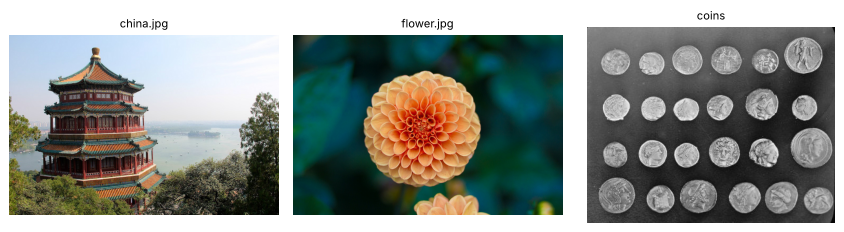

In [2]:
china  = to_tensor(load_sample_image("china.jpg"))     # colour photo, 427 × 640
flower = to_tensor(load_sample_image("flower.jpg"))    # colour photo, 427 × 640
coins  = to_tensor(skdata.coins())                     # grayscale, 303 × 384
for name, t in [("china", china), ("flower", flower), ("coins", coins)]:
    print(f"{name:7s} shape {tuple(t.shape)}  dtype {t.dtype}  min {t.min():.2f}  max {t.max():.2f}")
show([china, flower, coins], ["china.jpg", "flower.jpg", "coins"])

---
## 1. Images as tensors: shape, dtype and layout

A digital image is a grid of **pixels**; each pixel holds one number (grayscale) or several (colour channels).

| Convention | Shape | Used by |
|---|---|---|
| **HWC** (height, width, channels) | `(427, 640, 3)` | NumPy, PIL, OpenCV, matplotlib |
| **CHW** (channels, height, width) | `(3, 427, 640)` | **PyTorch** layers |
| **NCHW** (batch first) | `(N, 3, 427, 640)` | every `nn.Conv2d`, `F.conv2d`, `F.interpolate` |

| dtype | Range | Notes |
|---|---|---|
| `uint8` | 0 – 255 | how files store pixels; 1 byte each; arithmetic overflows! |
| `float32` | 0.0 – 1.0 | what we compute with; 4 bytes each |

In [3]:
raw = torch.from_numpy(load_sample_image("china.jpg").copy())
print("raw from file :", tuple(raw.shape), raw.dtype, "→ HWC, 0–255")
print("our tensor    :", tuple(china.shape), china.dtype, "→ CHW, 0–1")
batch = china.unsqueeze(0)
print("as a batch    :", tuple(batch.shape), "→ NCHW")
print(f"memory: uint8 {raw.numel()/1e6:.2f} MB vs float32 {china.numel()*4/1e6:.2f} MB")

# uint8 arithmetic wraps around — a classic bug
a = torch.tensor([250], dtype=torch.uint8)
print("\nuint8 250 + 10 =", (a + 10).item(), "  ← overflow wraps to 4!")
print("float 250 + 10 =", (a.float() + 10).item())

raw from file : (427, 640, 3) torch.uint8 → HWC, 0–255
our tensor    : (3, 427, 640) torch.float32 → CHW, 0–1
as a batch    : (1, 3, 427, 640) → NCHW
memory: uint8 0.82 MB vs float32 3.28 MB

uint8 250 + 10 = 4   ← overflow wraps to 4!
float 250 + 10 = 260.0


RGB at (200, 300): [0.173 0.094 0.09 ]


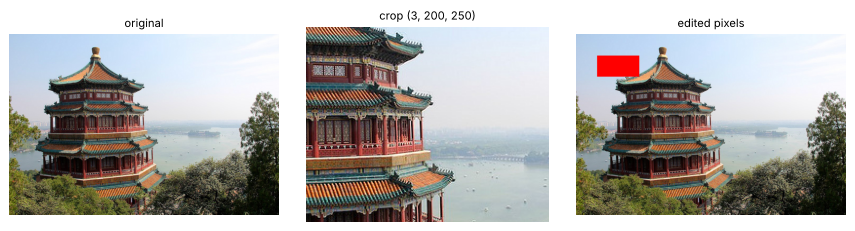

In [4]:
# Pixels are just tensor entries: index, slice, crop, edit
y, x = 200, 300
print("RGB at (200, 300):", china[:, y, x].numpy().round(3))
crop = china[:, 100:300, 200:450]                  # crop = slicing (rows, then columns)
patched = china.clone()
patched[:, 50:100, 50:150] = torch.tensor([1.0, 0.0, 0.0]).view(3, 1, 1)   # paint a red box
show([china, crop, patched], ["original", f"crop {tuple(crop.shape)}", "edited pixels"])

🔍 **What to notice**
* PyTorch wants **channels first**; `permute(2, 0, 1)` moves them, `unsqueeze(0)` adds the batch axis.
* Working in float32 avoids the uint8 overflow trap, at 4× the memory.
* Cropping is just slicing — no copy is made until you call `.clone()`.

✍️ **Exercise 1:** Crop a 128 × 128 square from the centre of `flower`, whatever the image size.

---
## 2. Colour spaces: RGB, grayscale and HSV

* **RGB**: three intensity planes. Most of what we see as “colour” is the *ratio* between them.
* **Grayscale (luma)**: a weighted sum matching human sensitivity (we see green best): `Y = 0.299 R + 0.587 G + 0.114 B` (ITU-R BT.601).
* **HSV**: **H**ue (which colour, 0–360°), **S**aturation (how pure), **V**alue (how bright). Great for selecting objects by colour,
  because hue barely changes with lighting.

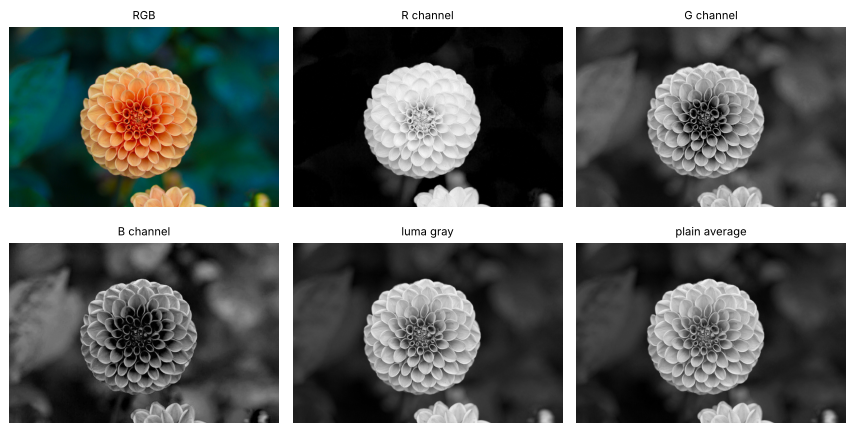

mean difference luma vs plain average: 0.0181


In [5]:
r, g, b = flower[0], flower[1], flower[2]
weights = torch.tensor([0.299, 0.587, 0.114]).view(3, 1, 1)
gray = (flower * weights).sum(0, keepdim=True)
naive = flower.mean(0, keepdim=True)
show([flower, r, g, b, gray, naive], ["RGB", "R channel", "G channel", "B channel", "luma gray", "plain average"], cols=3)
print("mean difference luma vs plain average:", round((gray - naive).abs().mean().item(), 4))

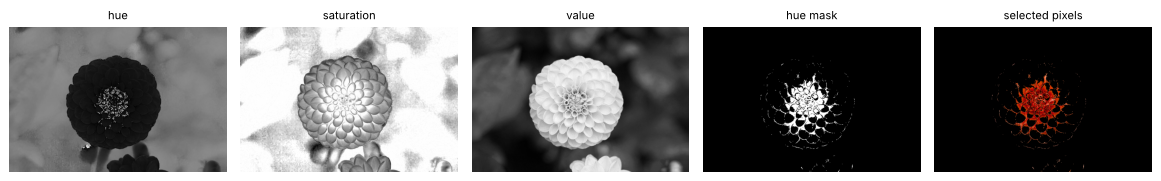

selected 4.0% of pixels


In [6]:
def rgb_to_hsv(img):
    # img: (3, H, W) in [0,1] -> H in [0,1) (×360 for degrees), S, V in [0,1]
    r, g, b = img[0], img[1], img[2]
    maxc, _ = img.max(0); minc, _ = img.min(0)
    v = maxc
    delta = maxc - minc
    s = torch.where(maxc > 0, delta / maxc.clamp(min=1e-8), torch.zeros_like(maxc))
    d = delta.clamp(min=1e-8)
    h = torch.where(maxc == r, ((g - b) / d) % 6,
        torch.where(maxc == g, (b - r) / d + 2, (r - g) / d + 4)) / 6.0
    h = torch.where(delta > 0, h, torch.zeros_like(h))
    return torch.stack([h, s, v])

hsv = rgb_to_hsv(flower)
# select "pink/red" petals by hue, ignoring dull and dark pixels
hue_deg = hsv[0] * 360
mask = (((hue_deg > 300) | (hue_deg < 20)) & (hsv[1] > 0.35) & (hsv[2] > 0.25)).float()
show([hsv[0], hsv[1], hsv[2], mask, flower * mask], ["hue", "saturation", "value", "hue mask", "selected pixels"], cols=5, size=2.6)
print(f"selected {mask.mean().item():.1%} of pixels")

In [7]:
# Check our HSV against scikit-image's implementation
from skimage.color import rgb2hsv
ref = torch.from_numpy(rgb2hsv(flower.permute(1, 2, 0).numpy())).permute(2, 0, 1).float()
print("max abs difference vs skimage:", round((hsv - ref).abs().max().item(), 6))

max abs difference vs skimage: 0.0


🔍 **What to notice**
* The petals are bright in **R**, the leaves in **G** — each channel is a grayscale image on its own.
* Luma and a plain average look similar but differ; luma is the standard because it matches perceived brightness.
* A few lines of tensor maths implement HSV, and it matches scikit-image. Selecting by hue picks the petals across shadows and highlights.

✍️ **Exercise 2:** Change the hue range to select the green leaves instead (hint: green ≈ 90°–150°).

---
## 3. Point operations: each output pixel depends only on the same input pixel

| Operation | Formula (values in [0,1]) | Effect |
|---|---|---|
| Brightness | `x + b` | shift everything up/down |
| Contrast | `(x − 0.5)·c + 0.5` | stretch around mid-grey |
| Gamma | `x ** γ` | γ < 1 brightens shadows, γ > 1 darkens |
| Negative | `1 − x` | invert |
| Threshold | `x > t` | binary mask |

Always **clamp** back to [0, 1] after brightness and contrast.

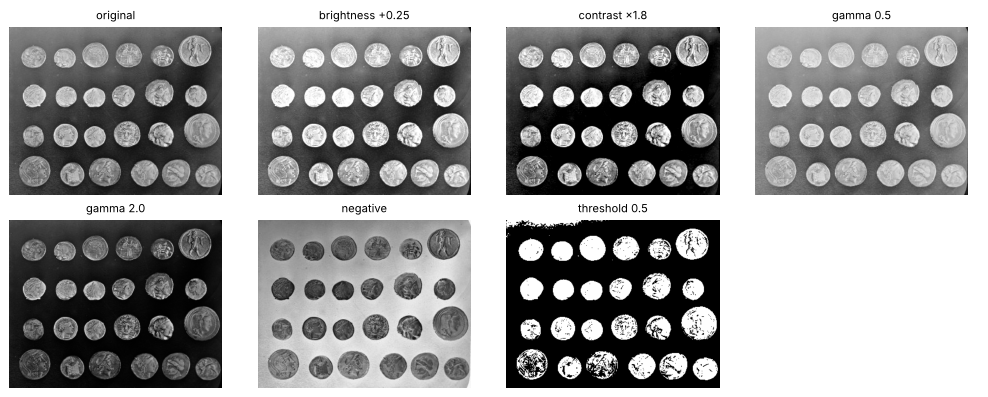

In [8]:
img = coins
ops = {
    "original":          img,
    "brightness +0.25":  (img + 0.25).clamp(0, 1),
    "contrast ×1.8":     ((img - 0.5) * 1.8 + 0.5).clamp(0, 1),
    "gamma 0.5":         img ** 0.5,
    "gamma 2.0":         img ** 2.0,
    "negative":          1 - img,
    "threshold 0.5":     (img > 0.5).float(),
}
show(list(ops.values()), list(ops.keys()), cols=4, size=2.8)

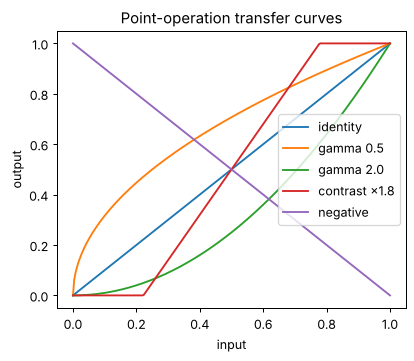

In [9]:
# Transfer curves: how each operation maps input → output
x = torch.linspace(0, 1, 256)
plt.figure(figsize=(5, 4))
for label, y_ in [("identity", x), ("gamma 0.5", x ** 0.5), ("gamma 2.0", x ** 2),
                  ("contrast ×1.8", ((x - .5) * 1.8 + .5).clamp(0, 1)), ("negative", 1 - x)]:
    plt.plot(x, y_, label=label)
plt.xlabel("input"); plt.ylabel("output"); plt.legend(); plt.title("Point-operation transfer curves"); plt.show()

🔍 **What to notice**
* Every point operation is just a **curve** from input to output; the plot explains each picture.
* Contrast stretching and brightening clip values at 0 and 1 — detail in the brightest coins is lost.
* A fixed threshold of 0.5 misses darker coins and keeps some bright background: the next section picks the threshold automatically.

✍️ **Exercise 3:** Write `levels(img, black, white)` that maps `black→0` and `white→1` linearly (clamped). Try black=0.2, white=0.8.

---
## 4. Histograms, equalisation and Otsu thresholding

The **histogram** counts how many pixels have each brightness. It shows at a glance whether an image is dark, bright or low-contrast.

* **Histogram equalisation** maps each value through the cumulative histogram (CDF), spreading values over the full range.
* **Otsu's method** picks the threshold that best separates two groups by maximising the *between-class variance*.

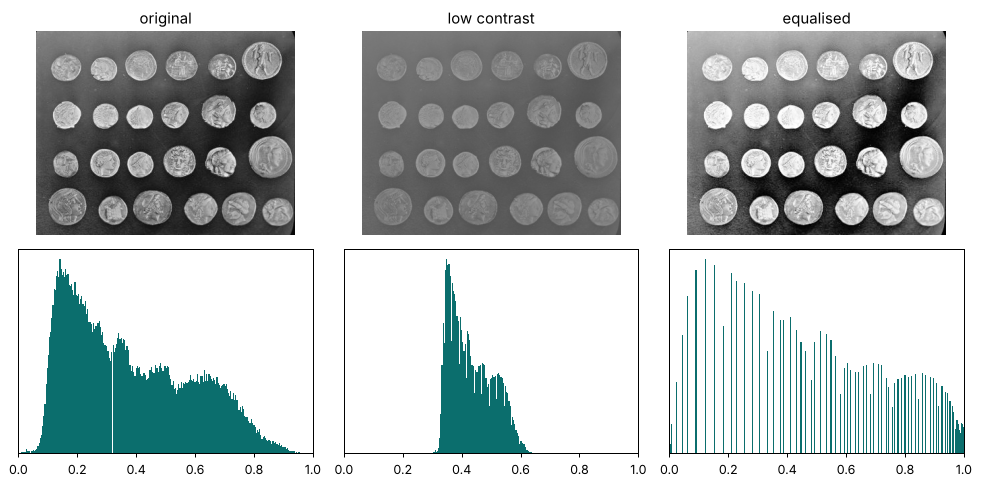

value range  low-contrast: 0.30–0.65   equalised: 0.00–1.00


In [10]:
def histogram(img, bins=256):
    return torch.histc(img.flatten(), bins=bins, min=0.0, max=1.0)

def equalize(img, bins=256):
    hist = histogram(img, bins)
    cdf = hist.cumsum(0); cdf = (cdf - cdf.min()) / (cdf.max() - cdf.min())
    idx = (img * (bins - 1)).round().long().clamp(0, bins - 1)
    return cdf[idx]

low = 0.3 + 0.35 * coins           # simulate a washed-out, low-contrast photo
eq = equalize(low)
fig, axes = plt.subplots(2, 3, figsize=(11, 5.5))
for col, (t, name) in enumerate([(coins, "original"), (low, "low contrast"), (eq, "equalised")]):
    axes[0, col].imshow(t.squeeze(), cmap="gray", vmin=0, vmax=1); axes[0, col].set_title(name); axes[0, col].axis("off")
    axes[1, col].bar(np.linspace(0, 1, 256), histogram(t).numpy(), width=1/256, color="#0B6E6D")
    axes[1, col].set_xlim(0, 1); axes[1, col].set_yticks([])
plt.tight_layout(); plt.show()
print(f"value range  low-contrast: {low.min():.2f}–{low.max():.2f}   equalised: {eq.min():.2f}–{eq.max():.2f}")

our Otsu threshold: 0.420 | scikit-image: 0.417


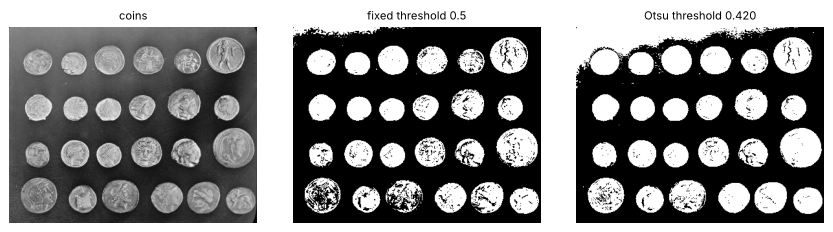

In [11]:
def otsu_threshold(img, bins=256):
    hist = histogram(img, bins); p = hist / hist.sum()
    levels = torch.linspace(0, 1, bins)
    w0 = p.cumsum(0); w1 = 1 - w0
    mu0 = (p * levels).cumsum(0) / w0.clamp(min=1e-8)
    mu_total = (p * levels).sum()
    mu1 = (mu_total - (p * levels).cumsum(0)) / w1.clamp(min=1e-8)
    between = w0 * w1 * (mu0 - mu1) ** 2              # between-class variance for every threshold
    return levels[between.argmax()].item(), between

t_otsu, between = otsu_threshold(coins)
from skimage.filters import threshold_otsu
print(f"our Otsu threshold: {t_otsu:.3f} | scikit-image: {threshold_otsu(coins.squeeze().numpy()):.3f}")
show([coins, (coins > 0.5).float(), (coins > t_otsu).float()],
     ["coins", "fixed threshold 0.5", f"Otsu threshold {t_otsu:.3f}"])

🔍 **What to notice**
* The low-contrast image's histogram is squeezed into a narrow band; equalisation spreads it across 0–1.
* Our Otsu implementation agrees with scikit-image to within one histogram bin, and finds more of the darker coins than the fixed 0.5.
* A single global threshold still struggles where lighting varies across the image — that's what *adaptive* (local) thresholds fix.

✍️ **Exercise 4:** Implement a local threshold: blur the image with a large box filter (Section 6) and mark pixels brighter than their local mean + 0.02.

---
## 5. Geometric transforms: resize, flip, rotate, affine warps

Geometric transforms move pixels instead of changing their values. The output needs values at positions that fall **between**
input pixels, so we **interpolate**:

* **nearest** — copy the closest pixel (blocky, keeps exact values; use for masks/labels)
* **bilinear** — weighted average of 4 neighbours (smooth)
* **bicubic** — 16 neighbours (sharper, can overshoot)

`F.interpolate` resizes; `F.affine_grid` + `F.grid_sample` apply any rotation/scale/shear/translation.

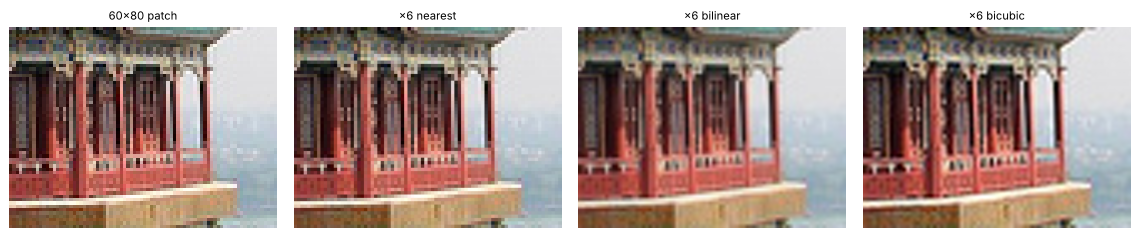

In [12]:
small = china[:, 180:240, 260:340].unsqueeze(0)       # a tiny 60×80 patch, NCHW
up = {m: F.interpolate(small, scale_factor=6, mode=m, **({} if m == "nearest" else {"align_corners": False}))
      for m in ["nearest", "bilinear", "bicubic"]}
show([small[0]] + [u[0].clamp(0, 1) for u in up.values()], ["60×80 patch"] + [f"×6 {m}" for m in up], cols=4)

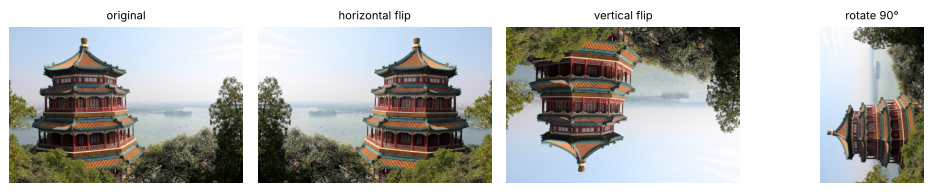

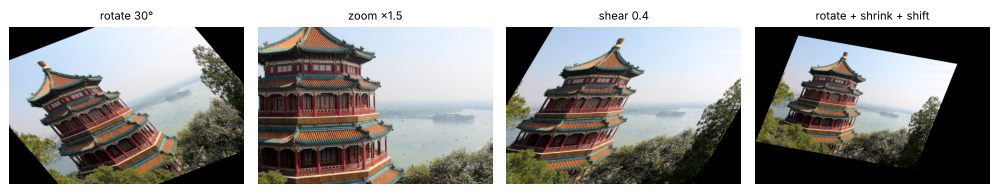

In [13]:
x = china.unsqueeze(0)
flips = [china, china.flip(-1), china.flip(-2), torch.rot90(china, 1, dims=(1, 2))]
show(flips, ["original", "horizontal flip", "vertical flip", "rotate 90°"], cols=4, size=2.8)

def affine(img, angle=0.0, scale=1.0, shear=0.0, tx=0.0, ty=0.0):
    # img: (N,C,H,W). angle in degrees; tx, ty in [-1,1] image units
    a = math.radians(angle)
    rot = torch.tensor([[math.cos(a), -math.sin(a)], [math.sin(a), math.cos(a)]])
    sh = torch.tensor([[1.0, shear], [0.0, 1.0]])
    A = (rot @ sh) / scale
    theta = torch.cat([A, torch.tensor([[tx], [ty]])], dim=1).unsqueeze(0).repeat(img.shape[0], 1, 1)
    grid = F.affine_grid(theta, img.shape, align_corners=False)     # where to sample each output pixel
    return F.grid_sample(img, grid, mode="bilinear", padding_mode="zeros", align_corners=False)

warps = [affine(x, angle=30), affine(x, scale=1.5), affine(x, shear=0.4), affine(x, angle=-15, scale=0.7, tx=0.2)]
show([w[0] for w in warps], ["rotate 30°", "zoom ×1.5", "shear 0.4", "rotate + shrink + shift"], cols=4, size=2.8)

🔍 **What to notice**
* Nearest-neighbour upscaling shows blocky pixels; bilinear is smooth but soft; bicubic is the sharpest.
* `grid_sample` works *backwards*: for each output pixel it asks “where do I come from?” — that's why the matrix is inverted by `/ scale`.
* Areas that map from outside the image are filled with zeros (black) — change `padding_mode` to `"border"` or `"reflection"`.
* Because these are differentiable PyTorch ops, a network can even **learn** the transform (Spatial Transformer Networks).

✍️ **Exercise 5:** Rotate by 45° with `padding_mode="reflection"`. Then rotate a *mask* — which interpolation mode must you use, and why?

---
## 6. Convolution: blur, sharpen, noise and denoising

**Convolution** slides a small grid of weights (a **kernel**) over the image; each output pixel is the weighted sum of its neighbourhood.
This one operation powers blurring, sharpening, edge detection — and every CNN.

`F.conv2d(input (N,C,H,W), weight (out_C, in_C/groups, kH, kW), padding, groups)`. With `groups=C` each colour channel is filtered separately.

Gaussian 7×7, sigma 1.5 (rounded):
 [[0.001 0.004 0.008 0.01  0.008 0.004 0.001]
 [0.004 0.012 0.024 0.03  0.024 0.012 0.004]
 [0.008 0.024 0.047 0.059 0.047 0.024 0.008]
 [0.01  0.03  0.059 0.073 0.059 0.03  0.01 ]
 [0.008 0.024 0.047 0.059 0.047 0.024 0.008]
 [0.004 0.012 0.024 0.03  0.024 0.012 0.004]
 [0.001 0.004 0.008 0.01  0.008 0.004 0.001]]
sums to 1.0


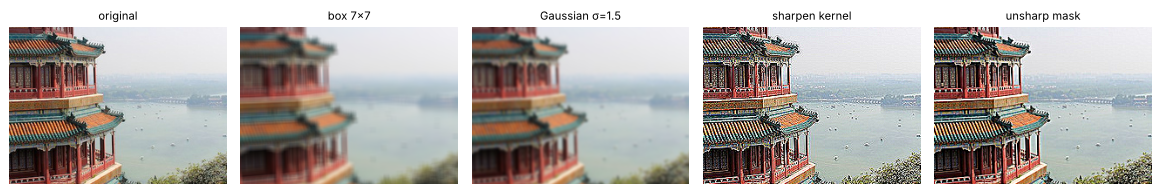

In [14]:
def filter2d(img, kernel, padding_mode="reflect"):
    # img (C,H,W); kernel (k,k) applied to every channel separately
    C = img.shape[0]; k = kernel.shape[-1]
    w = kernel.view(1, 1, k, k).repeat(C, 1, 1, 1)
    x = F.pad(img.unsqueeze(0), (k // 2,) * 4, mode=padding_mode)
    return F.conv2d(x, w, groups=C)[0]

def gaussian_kernel(size=7, sigma=1.5):
    ax = torch.arange(size) - size // 2
    g1 = torch.exp(-ax.float() ** 2 / (2 * sigma ** 2)); g1 /= g1.sum()
    return g1[:, None] * g1[None, :]                    # outer product → separable 2-D kernel

box = torch.ones(7, 7) / 49
gauss = gaussian_kernel(7, 1.5)
print("Gaussian 7×7, sigma 1.5 (rounded):\n", gauss.numpy().round(3))
print("sums to", round(gauss.sum().item(), 4))

sharpen = torch.tensor([[0., -1, 0], [-1, 5, -1], [0, -1, 0]])
blur = filter2d(china, gauss)
unsharp = (china + 1.5 * (china - blur)).clamp(0, 1)   # unsharp masking
crop = lambda t: t[:, 150:330, 220:470]
show([crop(china), crop(filter2d(china, box)), crop(blur), crop(filter2d(china, sharpen).clamp(0, 1)), crop(unsharp)],
     ["original", "box 7×7", "Gaussian σ=1.5", "sharpen kernel", "unsharp mask"], cols=5, size=2.6)

In [15]:
# Separable filters: a 2-D Gaussian = a horizontal pass + a vertical pass (much cheaper)
g1 = torch.exp(-(torch.arange(7) - 3).float() ** 2 / (2 * 1.5 ** 2)); g1 /= g1.sum()
img1 = coins
full = filter2d(img1, gauss)
x = F.pad(img1.unsqueeze(0), (3, 3, 3, 3), mode="reflect")
sep = F.conv2d(F.conv2d(x, g1.view(1, 1, 1, 7)), g1.view(1, 1, 7, 1))[0]
print("max difference 2-D vs separable:", f"{(full - sep).abs().max().item():.2e}")
print("multiplications per pixel: 2-D", 7 * 7, "| separable", 7 + 7)

max difference 2-D vs separable: 3.58e-07
multiplications per pixel: 2-D 49 | separable 14


### 6.1 Noise and denoising

PSNR in dB vs the clean image (higher = closer):
               Gaussian noise  salt & pepper
noisy                   22.02          17.31
Gaussian blur           26.18          24.26
median 3×3              25.85          28.19


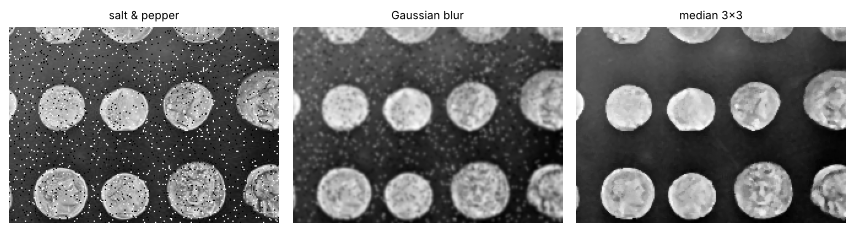

In [16]:
def psnr(a, b):
    mse = F.mse_loss(a, b)
    return (10 * torch.log10(1.0 / mse)).item()

def median_filter(img, k=3):
    # img (C,H,W): gather every k×k neighbourhood with unfold, take the median
    C, H, W = img.shape
    x = F.pad(img.unsqueeze(0), (k // 2,) * 4, mode="reflect")
    patches = F.unfold(x, kernel_size=k)                # (1, C*k*k, H*W)
    return patches.view(C, k * k, H, W).median(dim=1).values

torch.manual_seed(0)
clean = coins
gauss_noisy = (clean + 0.08 * torch.randn_like(clean)).clamp(0, 1)
sp = clean.clone(); r_ = torch.rand_like(sp)
sp[r_ < 0.03] = 0.0; sp[r_ > 0.97] = 1.0               # 6% salt-and-pepper

results = {}
for noise_name, noisy in [("Gaussian noise", gauss_noisy), ("salt & pepper", sp)]:
    results[noise_name] = {"noisy": psnr(noisy, clean),
                           "Gaussian blur": psnr(filter2d(noisy, gaussian_kernel(5, 1.0)), clean),
                           "median 3×3": psnr(median_filter(noisy, 3), clean)}
import pandas as pd
print("PSNR in dB vs the clean image (higher = closer):")
print(pd.DataFrame(results).round(2))
c2 = lambda t: t[:, 60:220, 60:280]
show([c2(sp), c2(filter2d(sp, gaussian_kernel(5, 1.0))), c2(median_filter(sp, 3))],
     ["salt & pepper", "Gaussian blur", "median 3×3"])

🔍 **What to notice**
* Box and Gaussian kernels both blur; the Gaussian is smoother (no blocky artefacts). Each kernel sums to 1 so brightness is kept.
* **Unsharp masking** adds back the detail that blurring removed: `sharp = img + k·(img − blur)`.
* A separable Gaussian gives the same result (difference ~1e-7) with 14 instead of 49 multiplications per pixel.
* For **Gaussian noise**, Gaussian blur is the better denoiser; for **salt & pepper**, the **median** filter wins by a wide margin,
  because one extreme pixel can't move a median.

✍️ **Exercise 6:** Plot PSNR of the Gaussian-noisy image after Gaussian blur for σ = 0.5, 1, 2, 3. Why does it rise and then fall?

---
## 7. Edge detection: Sobel, Laplacian and LoG

Edges are where brightness changes quickly — large **gradients**.

* **Sobel** kernels estimate the gradient in x and y; combine into **magnitude** `√(gx² + gy²)` and **direction** `atan2(gy, gx)`.
* **Laplacian** (second derivative) responds to rapid change in any direction, but also to noise.
* **LoG** (Laplacian of Gaussian): smooth first, then Laplacian — far more robust to noise.

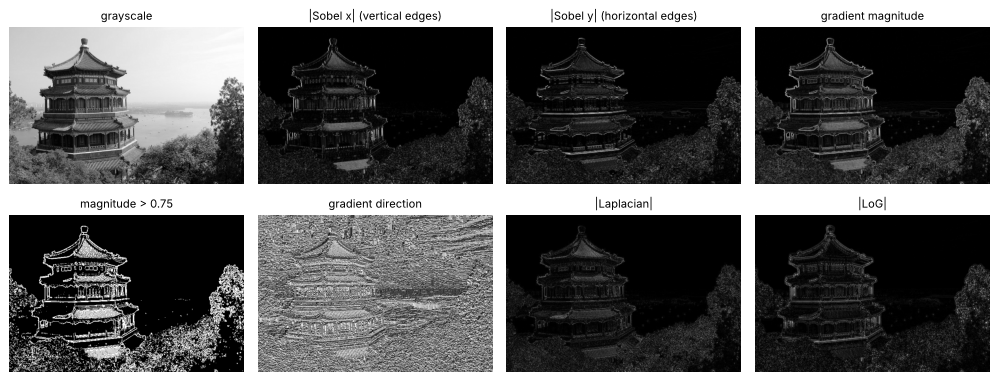

edge pixels: 16.4%


In [17]:
sobel_x = torch.tensor([[-1., 0, 1], [-2, 0, 2], [-1, 0, 1]])
sobel_y = sobel_x.T
laplacian = torch.tensor([[0., 1, 0], [1, -4, 1], [0, 1, 0]])

gray_china = (china * weights).sum(0, keepdim=True)
gx = filter2d(gray_china, sobel_x); gy = filter2d(gray_china, sobel_y)
mag = torch.sqrt(gx ** 2 + gy ** 2)
direction = torch.atan2(gy, gx)
edges = (mag > 0.75).float()
lap = filter2d(gray_china, laplacian)
log_ = filter2d(filter2d(gray_china, gaussian_kernel(7, 1.5)), laplacian)

show([gray_china, gx.abs(), gy.abs(), mag, edges, direction, lap.abs(), log_.abs()],
     ["grayscale", "|Sobel x| (vertical edges)", "|Sobel y| (horizontal edges)", "gradient magnitude",
      "magnitude > 0.75", "gradient direction", "|Laplacian|", "|LoG|"], cols=4, size=2.8)
print(f"edge pixels: {edges.mean().item():.1%}")

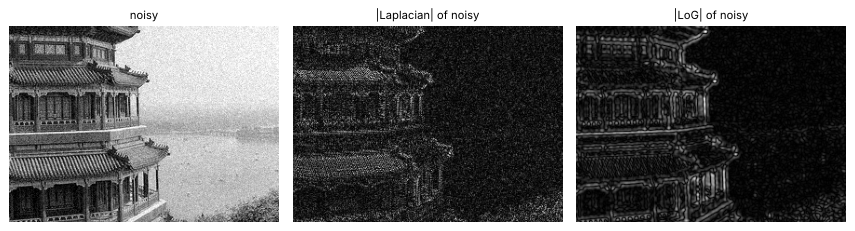

In [18]:
# Noise sensitivity: the Laplacian amplifies noise, LoG suppresses it
noisy_c = (gray_china + 0.05 * torch.randn_like(gray_china)).clamp(0, 1)
crop3 = lambda t: t[:, 120:330, 180:470]
show([crop3(noisy_c), crop3(filter2d(noisy_c, laplacian).abs()), crop3(filter2d(filter2d(noisy_c, gaussian_kernel(7, 1.5)), laplacian).abs())],
     ["noisy", "|Laplacian| of noisy", "|LoG| of noisy"])

🔍 **What to notice**
* Sobel-x lights up **vertical** edges (change along x), Sobel-y **horizontal** ones; the magnitude combines both.
* The direction image encodes edge orientation — the raw material for features like HOG.
* On the noisy image the plain Laplacian is mostly noise; smoothing first (LoG) recovers the structure.
  Full **Canny** adds non-maximum suppression and two thresholds on top of Sobel.

✍️ **Exercise 7:** Try thresholds 0.25, 0.75 and 1.5 on the magnitude (Sobel values can exceed 1). Then smooth with a Gaussian before Sobel — what changes?

---
## 8. Morphology: shaping binary masks

Morphology edits **shapes** in a binary mask using a small **structuring element** (here a k×k square):

* **Dilation** — grow white regions (max over the neighbourhood) → `F.max_pool2d`
* **Erosion** — shrink white regions (min over the neighbourhood) → `−max_pool(−x)`
* **Opening** = erode then dilate → removes small white specks
* **Closing** = dilate then erode → fills small black holes
* **Gradient** = dilate − erode → object outlines

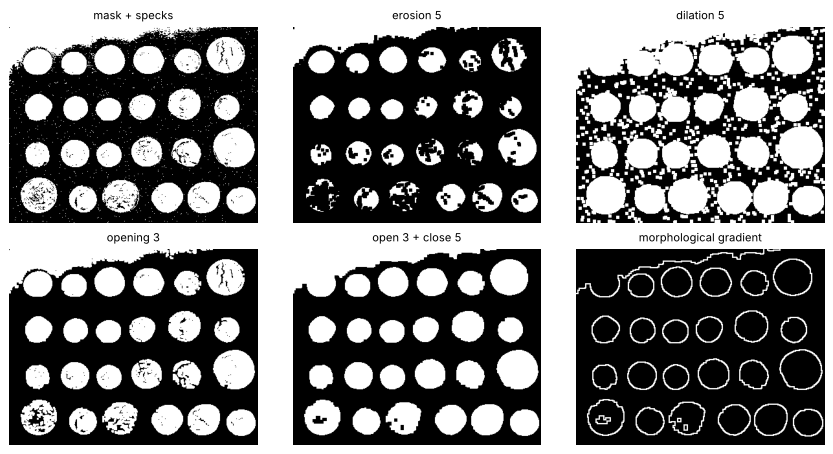

In [19]:
def dilate(mask, k=3): return F.max_pool2d(mask.unsqueeze(0), k, stride=1, padding=k // 2)[0]
def erode(mask, k=3):  return -F.max_pool2d(-mask.unsqueeze(0), k, stride=1, padding=k // 2)[0]
def opening(mask, k=3): return dilate(erode(mask, k), k)
def closing(mask, k=3): return erode(dilate(mask, k), k)

mask = (coins > t_otsu).float()
torch.manual_seed(1)
specks = mask.clone(); specks[torch.rand_like(specks) < 0.01] = 1.0   # add random white specks
cleaned = closing(opening(specks, 3), 5)
outline = dilate(cleaned, 3) - erode(cleaned, 3)
show([specks, erode(specks, 5), dilate(specks, 5), opening(specks, 3), cleaned, outline],
     ["mask + specks", "erosion 5", "dilation 5", "opening 3", "open 3 + close 5", "morphological gradient"], cols=3)

In [20]:
# Count objects: connected components on the cleaned mask (scipy does the labelling)
from scipy import ndimage
for name, m in [("Otsu mask", mask), ("mask + specks", specks), ("after open/close", cleaned)]:
    n = ndimage.label(m.squeeze().numpy())[1]
    print(f"{name:17s}: {n:4d} connected regions")

Otsu mask        :  154 connected regions
mask + specks    :  794 connected regions
after open/close :   25 connected regions


🔍 **What to notice**
* Erosion and dilation are just **min and max filters** — `max_pool2d` with stride 1 does the work.
* Random specks create hundreds of fake “objects”; **opening** removes them, **closing** fills holes inside coins.
* The region count drops from hundreds to a number close to the real coin count (24) — clean masks make measurement possible.

✍️ **Exercise 8:** Use a 3×3 *cross* structuring element instead of a square (hint: `F.unfold` + a mask, or `conv2d` with a cross kernel and `> 0`).

---
## 9. The frequency domain with `torch.fft`

Any image can be written as a sum of 2-D waves. The **Fourier transform** tells us how much of each frequency is present:
* **low frequencies** (centre of the shifted spectrum) = smooth areas, overall shape
* **high frequencies** (edges of the spectrum) = fine detail, edges, noise

**Convolution theorem:** convolving in space = multiplying in frequency. Large blurs are often faster this way.

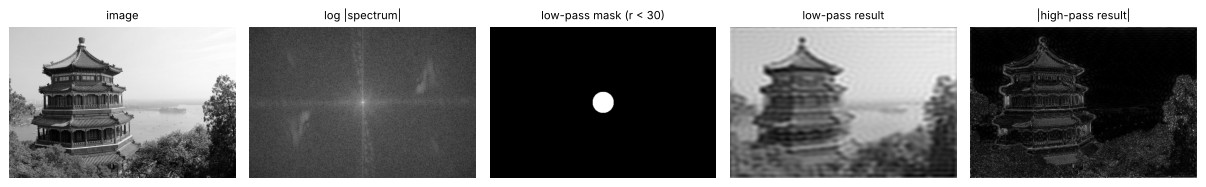

share of energy inside radius 30: 97.3%


In [21]:
img9 = gray_china[0]
H, W = img9.shape
spec = torch.fft.fftshift(torch.fft.fft2(img9))
log_mag = torch.log1p(spec.abs())

yy, xx = torch.meshgrid(torch.arange(H) - H // 2, torch.arange(W) - W // 2, indexing="ij")
radius = torch.sqrt(yy.float() ** 2 + xx.float() ** 2)
lowpass = (radius < 30).float()
highpass = 1 - lowpass
back = lambda S: torch.fft.ifft2(torch.fft.ifftshift(S)).real

low_img = back(spec * lowpass)
high_img = back(spec * highpass)
show([img9, log_mag, lowpass, low_img, high_img.abs()],
     ["image", "log |spectrum|", "low-pass mask (r < 30)", "low-pass result", "|high-pass result|"], cols=5, size=2.7)
energy = (spec.abs() ** 2)
print(f"share of energy inside radius 30: {(energy * lowpass).sum() / energy.sum():.1%}")

In [22]:
# Convolution theorem check: Gaussian blur by FFT == blur by conv2d (circular padding)
k = gaussian_kernel(15, 3.0)
pad = torch.zeros(H, W); pad[:15, :15] = k
pad = torch.roll(pad, shifts=(-7, -7), dims=(0, 1))          # centre the kernel at (0,0)
fft_blur = torch.fft.ifft2(torch.fft.fft2(img9) * torch.fft.fft2(pad)).real
conv_blur = filter2d(img9.unsqueeze(0), k, padding_mode="circular")[0]
print("max difference FFT vs conv2d:", f"{(fft_blur - conv_blur).abs().max().item():.2e}")

max difference FFT vs conv2d: 1.25e-06


🔍 **What to notice**
* The spectrum is brightest in the centre: most of an image's energy is in low frequencies (the printed share shows how much).
* Keeping only a small central disc gives a blurred image (with faint “ringing” from the sharp cut-off); the remaining high
  frequencies are exactly the edges and texture.
* FFT blur and conv2d blur agree to about 1e-6 (float32 rounding) — the convolution theorem in action. This is also why JPEG compression works: it
  stores low frequencies carefully and discards much of the high-frequency detail.

✍️ **Exercise 9:** Replace the hard low-pass disc with a Gaussian-shaped mask. Does the ringing disappear?

---
## 10. Pyramids, downsampling and aliasing

Shrinking an image by simply **skipping pixels** can create false patterns — **aliasing** (moiré) — because fine detail can't be
represented at the lower resolution. The fix: **blur first** (remove frequencies that won't fit), then downsample.
A **Gaussian pyramid** repeats blur-and-halve; CNNs build similar multi-scale features.

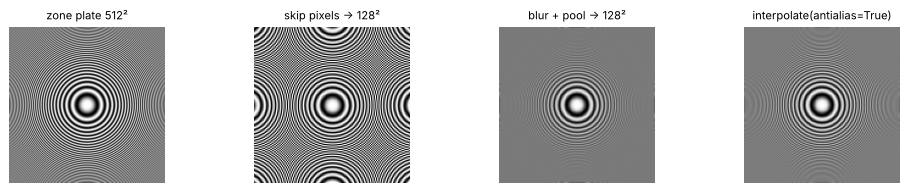

In [23]:
# A test pattern with very fine stripes (zone plate) shows aliasing clearly
n = 512
yy, xx = torch.meshgrid(torch.linspace(-1, 1, n), torch.linspace(-1, 1, n), indexing="ij")
zone = (0.5 + 0.5 * torch.cos(180 * (xx ** 2 + yy ** 2))).unsqueeze(0)
naive = zone[:, ::4, ::4]                                      # skip pixels
proper = F.avg_pool2d(filter2d(zone, gaussian_kernel(9, 2.0)).unsqueeze(0), 4)[0]
antialias = F.interpolate(zone.unsqueeze(0), size=(128, 128), mode="bilinear", antialias=True)[0]
show([zone, naive, proper, antialias],
     ["zone plate 512²", "skip pixels → 128²", "blur + pool → 128²", "interpolate(antialias=True)"], cols=4, size=2.8)

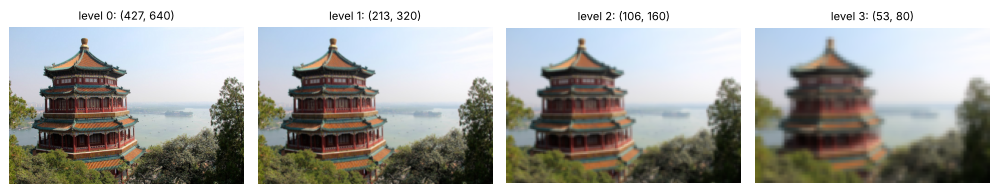

In [24]:
def gaussian_pyramid(img, levels=4):
    pyr = [img]
    for _ in range(levels - 1):
        pyr.append(F.avg_pool2d(filter2d(pyr[-1], gaussian_kernel(5, 1.0)).unsqueeze(0), 2)[0])
    return pyr

pyr = gaussian_pyramid(china, 4)
show(pyr, [f"level {i}: {tuple(p.shape[1:])}" for i, p in enumerate(pyr)], cols=4, size=2.8)

🔍 **What to notice**
* Skipping pixels turns the smooth rings into false, wrong-frequency rings (aliasing). Blurring first or `antialias=True` keeps it clean.
* Each pyramid level halves the size; together they let algorithms find objects at any scale.
* Use `antialias=True` whenever you shrink images for a dataset — the default `F.interpolate` does **not** antialias.

✍️ **Exercise 10:** Build a **Laplacian pyramid**: level − upsample(next level). Rebuild the original from it and check the error.

---
## 11. Image quality metrics: MSE, PSNR and SSIM

How close is a processed image to a reference?
* **MSE** — mean squared pixel difference. Simple, but blind to *structure*.
* **PSNR** = 10·log₁₀(1 / MSE) dB for images in [0,1]. Higher is better; ~30 dB+ is usually “good”.
* **SSIM** — compares local **luminance, contrast and structure** in small Gaussian windows; 1.0 = identical. Closer to human judgement.

                            MSE  PSNR dB    SSIM
brightness +0.07         0.0045  23.5025  0.9679
Gaussian noise σ=0.0525  0.0025  25.9513  0.6178
blur σ=2                 0.0077  21.1110  0.6214


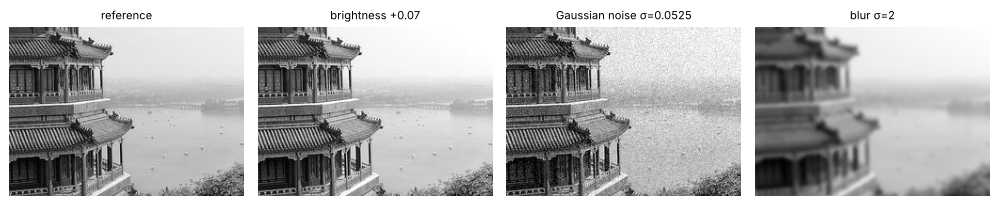

In [25]:
def ssim(a, b, C1=0.01 ** 2, C2=0.03 ** 2):
    # a, b: (1,H,W) in [0,1]; 11×11 Gaussian window, sigma 1.5 (standard choice)
    k = gaussian_kernel(11, 1.5)
    mu_a, mu_b = filter2d(a, k), filter2d(b, k)
    var_a = filter2d(a * a, k) - mu_a ** 2
    var_b = filter2d(b * b, k) - mu_b ** 2
    cov = filter2d(a * b, k) - mu_a * mu_b
    s = ((2 * mu_a * mu_b + C1) * (2 * cov + C2)) / ((mu_a ** 2 + mu_b ** 2 + C1) * (var_a + var_b + C2))
    return s.mean().item()

ref = gray_china
torch.manual_seed(0)
noise_sigma = 0.0525
candidates = {
    "brightness +0.07":       (ref + 0.07).clamp(0, 1),
    f"Gaussian noise σ={noise_sigma}": (ref + noise_sigma * torch.randn_like(ref)).clamp(0, 1),
    "blur σ=2":                filter2d(ref, gaussian_kernel(11, 2.0)),
}
rows = {n: {"MSE": F.mse_loss(t, ref).item(), "PSNR dB": psnr(t, ref), "SSIM": ssim(t, ref)} for n, t in candidates.items()}
print(pd.DataFrame(rows).T.round(4))
cr = lambda t: t[:, 150:330, 220:470]
show([cr(ref)] + [cr(t) for t in candidates.values()], ["reference"] + list(candidates.keys()), cols=4, size=2.8)

In [26]:
from skimage.metrics import structural_similarity
t = candidates["blur σ=2"]
print("our SSIM:", round(ssim(t, ref), 4), "| scikit-image:",
      round(structural_similarity(t.squeeze().numpy(), ref.squeeze().numpy(), data_range=1.0, gaussian_weights=True,
                                  sigma=1.5, use_sample_covariance=False), 4))

our SSIM: 0.6214 | scikit-image: 0.6213


🔍 **What to notice**
* A plain brightness shift barely changes the *structure*, so SSIM stays high even though MSE/PSNR call it a fair-sized error.
* Noise and blur damage structure, and SSIM drops for them — closer to how a person would rank the three images.
* Our 20-line SSIM matches scikit-image's Gaussian-window SSIM closely.
* SSIM is differentiable, so `1 − SSIM` is often used as a **training loss** for image restoration networks.

✍️ **Exercise 11:** Plot PSNR and SSIM for JPEG-like compression: low-pass the spectrum (Section 9) with radius 10, 20, 40, 80.

---
## 12. Batch pipelines and augmentation with torchvision

Real projects process **thousands** of images, so we work on **batches** (NCHW) and use `torchvision.transforms.v2`,
which runs on tensors (CPU or GPU) and keeps boxes/masks in sync with the image.

torchvision 0.29.2+cu132


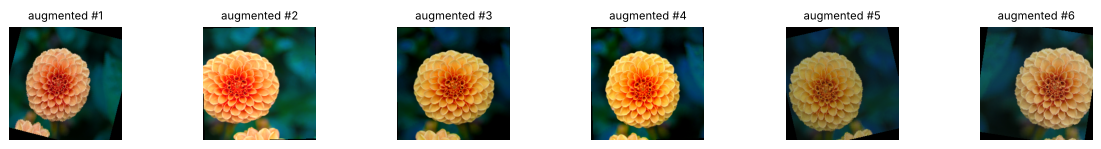

after Normalize: mean per channel [-0.93 -0.82 -0.91] | std [1.65 0.93 0.7 ]


In [27]:
import torchvision
from torchvision.transforms import v2
print("torchvision", torchvision.__version__)

torch.manual_seed(0)
augment = v2.Compose([
    v2.RandomResizedCrop(size=(224, 224), scale=(0.5, 1.0), antialias=True),
    v2.RandomHorizontalFlip(p=0.5),
    v2.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.05),
    v2.RandomRotation(degrees=15),
])
normalize = v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])   # ImageNet statistics

samples = [augment(flower) for _ in range(6)]
show(samples, [f"augmented #{i+1}" for i in range(6)], cols=6, size=2.2)
x = normalize(samples[0])
print("after Normalize: mean per channel", x.mean((1, 2)).numpy().round(2), "| std", x.std((1, 2)).numpy().round(2))

In [28]:
# Batched processing: one call on a whole batch vs a Python loop
# A typical dataset = many small images: 1,024 thumbnails of 32 × 48 pixels
torch.manual_seed(0)
thumb = v2.functional.resize(china, [32, 48], antialias=True)
batch = (thumb + 0.02 * torch.randn(1024, 3, 32, 48)).clamp(0, 1).to(device)       # (1024, 3, 32, 48)
k = gaussian_kernel(7, 1.5).view(1, 1, 7, 7).repeat(3, 1, 1, 1).to(device)

def blur_batch(b):
    return F.conv2d(F.pad(b, (3, 3, 3, 3), mode="reflect"), k, groups=3)

def best_time_ms(fn, repeats=5):
    fn()                                                  # warm-up
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter(); fn(); times.append(time.perf_counter() - t0)
    return 1000 * min(times)

out_b = blur_batch(batch)
out_l = torch.stack([blur_batch(im.unsqueeze(0))[0] for im in batch])
t_batch = best_time_ms(lambda: blur_batch(batch))
t_loop = best_time_ms(lambda: [blur_batch(im.unsqueeze(0)) for im in batch])
print(f"batch shape {tuple(batch.shape)} | same result: {torch.allclose(out_b, out_l, atol=1e-6)}")
print(f"one batched call: {t_batch:.0f} ms | loop of 1,024 calls: {t_loop:.0f} ms | speed-up ×{t_loop/t_batch:.1f} (on {device}, {torch.get_num_threads()} threads)")

batch shape (1024, 3, 32, 48) | same result: True
one batched call: 15 ms | loop of 1,024 calls: 115 ms | speed-up ×7.4 (on cpu, 2 threads)


🔍 **What to notice**
* Each call of the augmentation pipeline produces a different, still-realistic flower: random crop, flip, colour and rotation.
* `Normalize` uses the **ImageNet** mean and std, which pretrained models expect. They are not this image's own statistics,
  so its channel means are not exactly 0 (this pink-and-green flower is darker than the ImageNet average in every channel).
* The batched call gives exactly the same result as the loop. For a dataset of many small images it is clearly faster even on
  this 2-core CPU; on a GPU, batching is essential — thousands of images are processed in parallel.
  (For a handful of very large images on a small CPU the gain can disappear, so always measure.)

✍️ **Exercise 12:** Wrap `augment` in a `Dataset` class for a folder of images and load it with a `DataLoader(batch_size=32, num_workers=2)`.

---
## 13. From hand-made filters to learned filters

A convolution layer is just a set of learnable kernels. Here a single `nn.Conv2d(1, 1, 3)` starts from **random** weights and is trained
only to reproduce the Sobel-x output from Section 7. Does it rediscover the Sobel kernel?

random start kernel:
 [[-0.    0.18 -0.27]
 [-0.25 -0.13  0.09]
 [-0.01  0.26 -0.03]]



learned kernel after 300 steps:
 [[-1.02  0.02  0.99]
 [-1.97 -0.02  1.99]
 [-1.01 -0.    1.01]]
Sobel-x for comparison:
 [[-1.  0.  1.]
 [-2.  0.  2.]
 [-1.  0.  1.]]

loss: start 0.1948 → end 9.69e-06


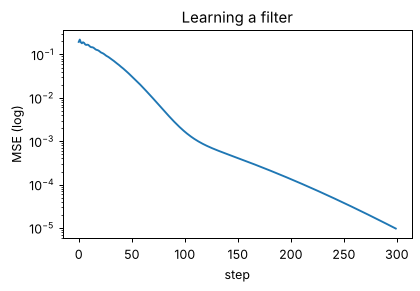

In [29]:
torch.manual_seed(0)
inp = F.pad(gray_china.unsqueeze(0), (1, 1, 1, 1), mode="reflect")    # (1,1,H+2,W+2)
target = filter2d(gray_china, sobel_x).unsqueeze(0)                  # what we want the layer to output

conv = nn.Conv2d(1, 1, kernel_size=3, bias=False)
print("random start kernel:\n", conv.weight.data[0, 0].numpy().round(2))
opt = torch.optim.Adam(conv.parameters(), lr=0.05)
losses = []
for step in range(300):
    loss = F.mse_loss(conv(inp), target)
    opt.zero_grad(); loss.backward(); opt.step()
    losses.append(loss.item())
print("\nlearned kernel after 300 steps:\n", conv.weight.data[0, 0].numpy().round(2))
print("Sobel-x for comparison:\n", sobel_x.numpy())
print(f"\nloss: start {losses[0]:.4f} → end {losses[-1]:.2e}")
plt.figure(figsize=(5, 3)); plt.semilogy(losses); plt.xlabel("step"); plt.ylabel("MSE (log)"); plt.title("Learning a filter"); plt.show()

🔍 **What to notice**
* From random numbers, gradient descent recovers the Sobel kernel almost exactly — the loss falls by many orders of magnitude.
* This is the bridge to deep learning: a CNN's first layer learns edge and colour filters like the ones we built by hand,
  and deeper layers combine them into textures, parts and objects — chosen by the **data**, not by us.
* Note: PyTorch's `conv2d` is technically *cross-correlation* (no kernel flip), so the learned kernel matches Sobel-x as written.

✍️ **Exercise 13:** Train a `Conv2d(1, 2, 3)` to output both Sobel-x and Sobel-y at once. Then try learning a 7×7 Gaussian blur.

---
## Summary

| Topic | Key tensor tools | Remember |
|---|---|---|
| Images as tensors | `permute`, `unsqueeze`, `float()/255` | PyTorch = CHW / NCHW, float32 in [0,1] |
| Colour | weighted sums, `max/min`, `torch.where` | luma 0.299/0.587/0.114; HSV to select by colour |
| Point ops | `+ * **`, `clamp`, comparisons | each is a transfer curve |
| Histograms | `histc`, `cumsum` | equalise with the CDF; Otsu picks the threshold |
| Geometry | `F.interpolate`, `affine_grid`, `grid_sample` | nearest for masks; mind padding |
| Convolution | `F.conv2d(groups=C)`, `F.pad`, `F.unfold` | Gaussian for noise, median for salt & pepper |
| Edges | Sobel, Laplacian, LoG | smooth before differentiating |
| Morphology | `max_pool2d` | opening removes specks, closing fills holes |
| Frequency | `torch.fft.fft2`, `fftshift` | low = shape, high = detail; conv ↔ multiply |
| Downsampling | `avg_pool2d`, `antialias=True` | blur before shrinking |
| Quality | MSE, PSNR, SSIM | SSIM tracks structure like people do |
| Pipelines | `transforms.v2`, batches | augment training data only; batch for speed |
| Learned filters | `nn.Conv2d` + gradient descent | CNNs learn the filters we used to design |